# Evaluating Matchup Features in NBA Shot Prediction

## Research question

Do historical defensive matchup features improve the performance of our existing NBA shot prediction model?

## Stage 1: Dataset validation

Before training, we verify that the original model-ready dataset and the new matchup-integrated dataset contain the same shots, outcomes and game information.

We will preserve the original chronological training, validation and test split.

In [12]:

from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project folder
ROOT = Path.cwd()

while not (ROOT / "data" / "processed").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Could not locate EclipseBasketballFall26.")
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"

ORIGINAL_PATH = DATA_DIR / "nba_shots_model_ready.parquet"
MATCHUP_PATH = DATA_DIR / "nba_shots_with_matchup_features_v2.parquet"

# Load both datasets
original = pd.read_parquet(ORIGINAL_PATH)
matchup = pd.read_parquet(MATCHUP_PATH)

print("=" * 65)
print("DATASET OVERVIEW")
print("=" * 65)

print("Original dataset:", original.shape)
print("Matchup dataset:", matchup.shape)

# Required matching columns
KEYS = ["game_id", "game_event_id"]
TARGET = "shot_made_flag"

for name, df in [("Original", original), ("Matchup", matchup)]:
    missing = [c for c in KEYS if c not in df.columns]
    if missing:
        raise ValueError(f"{name} dataset is missing keys: {missing}")

    print(f"\n{name} dataset")
    print("Duplicate shot keys:", df.duplicated(KEYS).sum())
    print("Missing shot keys:", df[KEYS].isna().any(axis=1).sum())

# Normalize keys so strings and numeric IDs can be matched safely.
def normalize_keys(df):
    result = df.copy()

    result["game_id"] = (
        result["game_id"].astype("string").str.strip().str.zfill(10)
    )

    result["game_event_id"] = (
        result["game_event_id"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    return result

original_check = normalize_keys(original)
matchup_check = normalize_keys(matchup)

if original_check.duplicated(KEYS).any():
    raise ValueError("Original dataset has duplicate normalized shot keys.")

if matchup_check.duplicated(KEYS).any():
    raise ValueError("Matchup dataset has duplicate normalized shot keys.")

# Match the two datasets using individual shot identifiers.
comparison = original_check[KEYS].merge(
    matchup_check[KEYS],
    on=KEYS,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("\n" + "=" * 65)
print("SHOT MATCHING RESULTS")
print("=" * 65)

print(comparison["_merge"].value_counts())

# Verify the shot outcomes are identical.
if TARGET in original.columns and TARGET in matchup.columns:
    target_check = original_check[
        KEYS + [TARGET]
    ].merge(
        matchup_check[KEYS + [TARGET]],
        on=KEYS,
        how="inner",
        suffixes=("_original", "_matchup"),
        validate="one_to_one"
    )

    target_mismatches = (
        target_check[f"{TARGET}_original"]
        != target_check[f"{TARGET}_matchup"]
    ).sum()

    print("\nShot outcome mismatches:", target_mismatches)

# Check opponent team IDs if available.
if "opponent_team_id" in original.columns and "opponent_team_id" in matchup.columns:
    opponent_check = original_check[
        KEYS + ["opponent_team_id"]
    ].merge(
        matchup_check[KEYS + ["opponent_team_id"]],
        on=KEYS,
        how="inner",
        suffixes=("_original", "_matchup"),
        validate="one_to_one"
    )

    opponent_mismatches = (
        opponent_check["opponent_team_id_original"]
        .astype("string")
        != opponent_check["opponent_team_id_matchup"]
        .astype("string")
    ).sum()

    print("Opponent team mismatches:", opponent_mismatches)

# Identify the six new matchup features.
MATCHUP_FEATURES = [
    "matchup_defense_prior_fg_pct_smoothed",
    "matchup_defense_prior_three_pct_smoothed",
    "matchup_defense_prior_fg_attempts",
    "matchup_defense_prior_three_attempts",
    "matchup_defense_prior_games",
    "matchup_defense_has_history"
]

missing_features = [
    c for c in MATCHUP_FEATURES if c not in matchup.columns
]

print("\nMissing matchup features:", missing_features)

print("\n" + "=" * 65)
print("VALIDATION COMPLETE")
print("=" * 65)

print("Project folder:", ROOT)


DATASET OVERVIEW
Original dataset: (467537, 35)
Matchup dataset: (467537, 94)

Original dataset
Duplicate shot keys: 0
Missing shot keys: 0

Matchup dataset
Duplicate shot keys: 0
Missing shot keys: 0

SHOT MATCHING RESULTS
_merge
both          467537
left_only          0
right_only         0
Name: count, dtype: int64

Shot outcome mismatches: 0
Opponent team mismatches: 0

Missing matchup features: []

VALIDATION COMPLETE
Project folder: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26


In [13]:

import json
from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------
# 1. Define the six new matchup features
# ------------------------------------------------

MATCHUP_FEATURES = [
    "matchup_defense_prior_fg_pct_smoothed",
    "matchup_defense_prior_three_pct_smoothed",
    "matchup_defense_prior_fg_attempts",
    "matchup_defense_prior_three_attempts",
    "matchup_defense_prior_games",
    "matchup_defense_has_history"
]

MATCHUP_RATE_FEATURES = MATCHUP_FEATURES[:2]

KEYS = ["game_id", "game_event_id"]
TARGET = "shot_made_flag"

# ------------------------------------------------
# 2. Load Hayden's original feature configuration
# ------------------------------------------------

FEATURE_SETS_PATH = ROOT / "reports" / "feature_sets.json"

with open(FEATURE_SETS_PATH, "r") as file:
    feature_sets = json.load(file)

BASE_FEATURES = feature_sets["plus_offense_and_defense"]

print("Original feature count:", len(BASE_FEATURES))
print("New matchup feature count:", len(MATCHUP_FEATURES))

# ------------------------------------------------
# 3. Verify all required columns exist
# ------------------------------------------------

missing_base = [
    column for column in BASE_FEATURES
    if column not in original_check.columns
]

missing_matchup = [
    column for column in MATCHUP_FEATURES
    if column not in matchup_check.columns
]

print("\nMissing original features:", missing_base)
print("Missing matchup features:", missing_matchup)

if missing_base or missing_matchup:
    raise ValueError(
        "Some required features are missing. Do not continue to modeling."
    )

# ------------------------------------------------
# 4. Combine the two datasets using shot IDs
# ------------------------------------------------

modeling_data = original_check.merge(
    matchup_check[KEYS + MATCHUP_FEATURES],
    on=KEYS,
    how="inner",
    validate="one_to_one"
)

print("\nCombined dataset shape:", modeling_data.shape)

# ------------------------------------------------
# 5. Reconstruct Hayden's chronological split
# ------------------------------------------------

modeling_data["game_date"] = pd.to_datetime(
    modeling_data["game_date"],
    errors="coerce",
    utc=True
).dt.tz_convert(None).dt.normalize()

conditions = [
    modeling_data["game_date"] <= pd.Timestamp("2026-01-13"),

    modeling_data["game_date"].between(
        "2026-01-14", "2026-03-23"
    ),

    modeling_data["game_date"].between(
        "2026-03-24", "2026-06-13"
    )
]

choices = ["train", "validation", "test"]

modeling_data["split"] = np.select(
    conditions,
    choices,
    default="outside"
)

outside_count = (modeling_data["split"] == "outside").sum()

print("\nShots outside the expected date ranges:", outside_count)

if outside_count > 0:
    print(
        modeling_data.loc[
            modeling_data["split"] == "outside",
            "game_date"
        ].value_counts().sort_index()
    )
    raise ValueError("Some shots fall outside the expected split dates.")

# ------------------------------------------------
# 6. Check the split against Hayden's summary
# ------------------------------------------------

split_summary = (
    modeling_data.groupby("split", sort=False)
    .agg(
        shots=(TARGET, "size"),
        games=("game_id", "nunique"),
        first_date=("game_date", "min"),
        last_date=("game_date", "max"),
        make_rate=(TARGET, "mean")
    )
)

display(split_summary)

expected = {
    "train": (340288, 1909),
    "validation": (85110, 480),
    "test": (42139, 240)
}

for split_name, (expected_shots, expected_games) in expected.items():

    actual_shots = int(split_summary.loc[split_name, "shots"])
    actual_games = int(split_summary.loc[split_name, "games"])

    assert actual_shots == expected_shots, (
        f"{split_name}: expected {expected_shots} shots, got {actual_shots}"
    )

    assert actual_games == expected_games, (
        f"{split_name}: expected {expected_games} games, got {actual_games}"
    )

# Confirm that no game appears in multiple splits.
assert modeling_data.groupby("game_id")["split"].nunique().max() == 1

# ------------------------------------------------
# 7. Define the three experiments
# ------------------------------------------------

FEATURE_CONFIGURATIONS = {
    "A_original": BASE_FEATURES,

    "B_matchup_percentages": (
        BASE_FEATURES + MATCHUP_RATE_FEATURES
    ),

    "C_all_matchup_features": (
        BASE_FEATURES + MATCHUP_FEATURES
    )
}

print("\nEXPERIMENT CONFIGURATIONS")
print("=" * 55)

for experiment, features in FEATURE_CONFIGURATIONS.items():

    print(f"\n{experiment}")
    print("Number of features:", len(features))

    assert len(features) == len(set(features))

    missing = [
        column for column in features
        if column not in modeling_data.columns
    ]

    assert not missing, f"Missing columns: {missing}"

# ------------------------------------------------
# 8. Save a NEW combined dataset
# ------------------------------------------------

OUTPUT_PATH = (
    DATA_DIR / "nba_shots_modeling_experiments.parquet"
)

modeling_data.to_parquet(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 65)
print("MODELING DATASET CREATED SUCCESSFULLY")
print("=" * 65)

print("Saved to:", OUTPUT_PATH)
print("Final rows:", len(modeling_data))
print("Original features:", len(BASE_FEATURES))
print("Experiment A:", len(FEATURE_CONFIGURATIONS["A_original"]))
print("Experiment B:", len(FEATURE_CONFIGURATIONS["B_matchup_percentages"]))
print("Experiment C:", len(FEATURE_CONFIGURATIONS["C_all_matchup_features"]))
print("\nAll three chronological splits match Hayden's summary.")


Original feature count: 27
New matchup feature count: 6

Missing original features: []
Missing matchup features: []

Combined dataset shape: (467537, 41)

Shots outside the expected date ranges: 0


,shots,games,first_date,last_date,make_rate
split,,,,,
train,340288,1909,2024-10-22,2026-01-13,0.46741
validation,85110,480,2026-01-14,2026-03-23,0.469722
test,42139,240,2026-03-24,2026-06-13,0.47087



EXPERIMENT CONFIGURATIONS

A_original
Number of features: 27

B_matchup_percentages
Number of features: 29

C_all_matchup_features
Number of features: 33

MODELING DATASET CREATED SUCCESSFULLY
Saved to: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\data\processed\nba_shots_modeling_experiments.parquet
Final rows: 467537
Original features: 27
Experiment A: 27
Experiment B: 29
Experiment C: 33

All three chronological splits match Hayden's summary.


## Stage 2: XGBoost model experiments

We will use XGBoost to compare three feature configurations.

The first experiment uses the original 27 features. The second adds two historical matchup shooting percentages. The third adds all six matchup features.

All experiments will use the same training data, validation data and model settings so that we can make a fair comparison.

In [14]:

import sys
import importlib.util
import sklearn

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

if importlib.util.find_spec("xgboost") is None:
    print("\nXGBoost is NOT installed.")
    print("Install it using the PowerShell command below.")
else:
    import xgboost as xgb
    print("XGBoost:", xgb.__version__)
    print("\nXGBoost is ready!")


Python: c:\Program Files\Python312\python.exe
Scikit-learn: 1.9.1
XGBoost: 3.4.1

XGBoost is ready!


In [15]:

# Separate training and validation data.
# We deliberately do not create or inspect the test dataset here.

train_data = modeling_data.loc[
    modeling_data["split"] == "train"
].copy()

validation_data = modeling_data.loc[
    modeling_data["split"] == "validation"
].copy()

# Check the target variable.
TARGET = "shot_made_flag"

assert TARGET in modeling_data.columns
assert set(train_data[TARGET].unique()) == {0, 1}
assert set(validation_data[TARGET].unique()) == {0, 1}

# Check all three feature configurations.
for experiment, features in FEATURE_CONFIGURATIONS.items():

    train_missing = train_data[features].isna().sum().sum()
    validation_missing = validation_data[features].isna().sum().sum()

    print(f"\n{experiment}")
    print("Features:", len(features))
    print("Missing training values:", train_missing)
    print("Missing validation values:", validation_missing)

    assert train_missing == 0
    assert validation_missing == 0

print("\nTRAINING DATA:", train_data.shape)
print("VALIDATION DATA:", validation_data.shape)

print("\nTraining make percentage:",
      round(train_data[TARGET].mean() * 100, 2), "%")

print("Validation make percentage:",
      round(validation_data[TARGET].mean() * 100, 2), "%")

print("\nAll experiment datasets are ready.")



A_original
Features: 27
Missing training values: 0
Missing validation values: 0

B_matchup_percentages
Features: 29
Missing training values: 0
Missing validation values: 0

C_all_matchup_features
Features: 33
Missing training values: 0
Missing validation values: 0

TRAINING DATA: (340288, 41)
VALIDATION DATA: (85110, 41)

Training make percentage: 46.74 %
Validation make percentage: 46.97 %

All experiment datasets are ready.


## Stage 3: Training the XGBoost models

We train three XGBoost models using different feature configurations.

All three models use the same training shots and model settings. The validation dataset is used only to compare their predictions.

We do not use the reserved test dataset during this stage.

In [16]:

import time
import joblib
import xgboost as xgb

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# ------------------------------------------------
# 1. Prepare target variables
# ------------------------------------------------

y_train = train_data[TARGET].astype(int).to_numpy()
y_validation = validation_data[TARGET].astype(int).to_numpy()

# These columns contain categories rather than numerical measurements.
CATEGORICAL_CANDIDATES = [
    "shot_type",
    "shot_zone_basic",
    "shot_zone_area",
    "season"
]

# ------------------------------------------------
# 2. Set the XGBoost configuration
# ------------------------------------------------

XGB_PARAMS = {
    "n_estimators": 400,
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "n_jobs": 4,
    "random_state": 42,
    "verbosity": 0
}

print("XGBoost version:", xgb.__version__)
print("Model settings:")
print(XGB_PARAMS)

# ------------------------------------------------
# 3. Create a pipeline for each experiment
# ------------------------------------------------

def create_xgb_pipeline(features):

    categorical_features = [
        col for col in CATEGORICAL_CANDIDATES
        if col in features
    ]

    numerical_features = [
        col for col in features
        if col not in categorical_features
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            (
                "numerical",
                "passthrough",
                numerical_features
            )
        ],
        remainder="drop"
    )

    model = xgb.XGBClassifier(**XGB_PARAMS)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    return pipeline


# ------------------------------------------------
# 4. Create output folders
# ------------------------------------------------

MODEL_DIR = ROOT / "models" / "matchup_experiments"
REPORT_DIR_EXPERIMENTS = ROOT / "reports" / "matchup_experiments"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR_EXPERIMENTS.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------
# 5. Train all three experiments
# ------------------------------------------------

trained_models = {}
experiment_predictions = {}
training_results = []

for experiment_name, features in FEATURE_CONFIGURATIONS.items():

    print("\n" + "=" * 65)
    print("TRAINING:", experiment_name)
    print("Number of features:", len(features))
    print("=" * 65)

    X_train = train_data[features].copy()
    X_validation = validation_data[features].copy()

    # Convert categorical values to consistent strings.
    for col in CATEGORICAL_CANDIDATES:
        if col in features:
            X_train[col] = X_train[col].astype(str)
            X_validation[col] = X_validation[col].astype(str)

    # Convert remaining columns to numerical values.
    numerical_features = [
        col for col in features
        if col not in CATEGORICAL_CANDIDATES
    ]

    X_train[numerical_features] = (
        X_train[numerical_features].astype("float32")
    )

    X_validation[numerical_features] = (
        X_validation[numerical_features].astype("float32")
    )

    # Build model.
    pipeline = create_xgb_pipeline(features)

    # Train model.
    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_seconds = time.time() - start_time

    print(f"Training completed in {training_seconds:.2f} seconds.")

    # Generate validation probabilities.
    probabilities = pipeline.predict_proba(X_validation)[:, 1]

    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    trained_models[experiment_name] = pipeline
    experiment_predictions[experiment_name] = probabilities

    # Save model.
    model_path = MODEL_DIR / f"{experiment_name}.joblib"
    joblib.dump(pipeline, model_path, compress=3)

    training_results.append({
        "experiment": experiment_name,
        "features": len(features),
        "training_seconds": training_seconds,
        "model_path": str(model_path)
    })

    print("Model saved:", model_path)

# ------------------------------------------------
# 6. Calculate validation metrics
# ------------------------------------------------

def calculate_ece(y_true, probabilities, bins=10):

    bin_edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.minimum(
        np.digitize(probabilities, bin_edges) - 1,
        bins - 1
    )

    ece = 0.0

    for bin_number in range(bins):

        mask = bin_indices == bin_number

        if mask.sum() == 0:
            continue

        actual_rate = y_true[mask].mean()
        predicted_rate = probabilities[mask].mean()

        ece += (
            mask.mean()
            * abs(actual_rate - predicted_rate)
        )

    return ece


metrics_rows = []

for experiment_name, probabilities in experiment_predictions.items():

    metrics_rows.append({

        "experiment": experiment_name,

        "features": len(
            FEATURE_CONFIGURATIONS[experiment_name]
        ),

        "log_loss": log_loss(
            y_validation,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_validation,
            probabilities
        ),

        "roc_auc": roc_auc_score(
            y_validation,
            probabilities
        ),

        "ece": calculate_ece(
            y_validation,
            probabilities
        ),

        "calibration_bias": (
            probabilities.mean() - y_validation.mean()
        )
    })


# ------------------------------------------------
# 7. Display and save results
# ------------------------------------------------

results = pd.DataFrame(metrics_rows)

results = results.sort_values(
    "log_loss",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 75)
print("XGBOOST VALIDATION RESULTS")
print("=" * 75)

display(results.round(6))

results.to_csv(
    REPORT_DIR_EXPERIMENTS / "xgboost_validation_results.csv",
    index=False
)

# Save validation predictions for later analysis.
prediction_output = validation_data[
    KEYS + ["game_date", TARGET]
].copy()

for experiment_name, probabilities in experiment_predictions.items():
    prediction_output[experiment_name] = probabilities

prediction_output.to_parquet(
    REPORT_DIR_EXPERIMENTS / "validation_predictions.parquet",
    index=False
)

pd.DataFrame(training_results).to_csv(
    REPORT_DIR_EXPERIMENTS / "training_times.csv",
    index=False
)

print("\nAll three models trained successfully.")
print("Results saved in:", REPORT_DIR_EXPERIMENTS)


XGBoost version: 3.4.1
Model settings:
{'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5, 'reg_lambda': 5, 'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_jobs': 4, 'random_state': 42, 'verbosity': 0}

TRAINING: A_original
Number of features: 27
Training completed in 9.09 seconds.
Model saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments\A_original.joblib

TRAINING: B_matchup_percentages
Number of features: 29
Training completed in 8.61 seconds.
Model saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments\B_matchup_percentages.joblib

TRAINING: C_all_matchup_features
Number of features: 33
Training completed in 12.81 seconds.
Model saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments\C_all_matchup_features.joblib

XGBOOST VALIDATION RESUL

,experiment,features,log_loss,brier_score,roc_auc,ece,calibration_bias
0,B_matchup_percentages,29,0.647181,0.227959,0.653903,0.014615,0.013904
1,C_all_matchup_features,33,0.647187,0.227962,0.652463,0.005455,0.004734
2,A_original,27,0.647283,0.227979,0.654020,0.016402,0.015517



All three models trained successfully.
Results saved in: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_experiments


## Stage 4: Comparing model performance across games

The three XGBoost experiments have produced very similar validation results.

We use a paired game-level bootstrap to examine whether the differences in performance are consistent across games.

Each bootstrap sample contains 480 games selected with replacement. All shots belonging to a selected game are kept together.

We compare the two matchup experiments against the original model using Log Loss, Brier Score, ROC-AUC and calibration.

The reserved test dataset remains untouched.

In [17]:

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# ------------------------------------------------
# 1. Prepare validation outcomes and predictions
# ------------------------------------------------

y = validation_data[TARGET].astype(int).to_numpy()

predictions = {
    name: np.asarray(probabilities, dtype=float)
    for name, probabilities in experiment_predictions.items()
}

MODEL_NAMES = [
    "A_original",
    "B_matchup_percentages",
    "C_all_matchup_features"
]

for name in MODEL_NAMES:
    assert name in predictions
    assert len(predictions[name]) == len(y)
    assert np.isfinite(predictions[name]).all()

# Confirm all predictions are valid probabilities.
for name, probabilities in predictions.items():
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

# ------------------------------------------------
# 2. Identify the validation games
# ------------------------------------------------

game_ids = validation_data["game_id"].astype(str).to_numpy()

unique_games, game_codes = np.unique(
    game_ids,
    return_inverse=True
)

N_GAMES = len(unique_games)

print("Validation shots:", len(y))
print("Unique validation games:", N_GAMES)

assert N_GAMES == 480

# ------------------------------------------------
# 3. Define metrics using game weights
# ------------------------------------------------

def weighted_ece(y_true, probabilities, weights, bins=10):

    edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.digitize(
        probabilities,
        edges[1:-1]
    )

    total_weight = weights.sum()
    ece = 0.0

    for bin_number in range(bins):

        mask = (
            (bin_indices == bin_number)
            & (weights > 0)
        )

        if not mask.any():
            continue

        bin_weights = weights[mask]
        bin_weight = bin_weights.sum()

        actual_rate = np.average(
            y_true[mask],
            weights=bin_weights
        )

        predicted_rate = np.average(
            probabilities[mask],
            weights=bin_weights
        )

        ece += (
            bin_weight / total_weight
            * abs(actual_rate - predicted_rate)
        )

    return float(ece)


def calculate_weighted_metrics(y_true, probabilities, weights):

    return {
        "log_loss": log_loss(
            y_true,
            probabilities,
            sample_weight=weights,
            labels=[0, 1]
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities,
            sample_weight=weights
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
            sample_weight=weights
        ),

        "ece": weighted_ece(
            y_true,
            probabilities,
            weights
        ),

        "absolute_calibration_bias": abs(
            np.average(
                probabilities - y_true,
                weights=weights
            )
        )
    }


# ------------------------------------------------
# 4. Calculate the original validation scores
# ------------------------------------------------

unit_weights = np.ones(len(y))

point_scores = {
    name: calculate_weighted_metrics(
        y,
        predictions[name],
        unit_weights
    )
    for name in MODEL_NAMES
}

print("\nOriginal validation scores:")
display(pd.DataFrame(point_scores).T.round(6))


# ------------------------------------------------
# 5. Run paired game-level bootstrap
# ------------------------------------------------

N_BOOTSTRAPS = 1000
SEED = 20261123

rng = np.random.default_rng(SEED)

# Store the improvements of B and C over A.
improvement_records = []

BASELINE = "A_original"

CANDIDATES = [
    "B_matchup_percentages",
    "C_all_matchup_features"
]

LOWER_IS_BETTER = [
    "log_loss",
    "brier_score",
    "ece",
    "absolute_calibration_bias"
]

HIGHER_IS_BETTER = [
    "roc_auc"
]

for candidate in CANDIDATES:

    for metric in LOWER_IS_BETTER + HIGHER_IS_BETTER:

        improvement_records.append({
            "candidate": candidate,
            "metric": metric,
            "improvements": []
        })


# Run the bootstrap.
for bootstrap_number in range(N_BOOTSTRAPS):

    # Select 480 games with replacement.
    sampled_games = rng.integers(
        low=0,
        high=N_GAMES,
        size=N_GAMES
    )

    # Count how often each game was selected.
    game_multiplicities = np.bincount(
        sampled_games,
        minlength=N_GAMES
    )

    # Give every shot its game's selection weight.
    shot_weights = game_multiplicities[game_codes].astype(float)

    # Calculate all models on the SAME sampled games.
    bootstrap_scores = {
        name: calculate_weighted_metrics(
            y,
            predictions[name],
            shot_weights
        )
        for name in MODEL_NAMES
    }

    baseline_scores = bootstrap_scores[BASELINE]

    # Compare each candidate against the original model.
    for record in improvement_records:

        candidate_scores = bootstrap_scores[
            record["candidate"]
        ]

        metric = record["metric"]

        if metric in LOWER_IS_BETTER:
            improvement = (
                baseline_scores[metric]
                - candidate_scores[metric]
            )
        else:
            improvement = (
                candidate_scores[metric]
                - baseline_scores[metric]
            )

        record["improvements"].append(improvement)

    if (bootstrap_number + 1) % 100 == 0:
        print(
            f"Completed {bootstrap_number + 1}/{N_BOOTSTRAPS} "
            "bootstrap samples."
        )


# ------------------------------------------------
# 6. Calculate confidence intervals
# ------------------------------------------------

summary_rows = []

for record in improvement_records:

    values = np.asarray(record["improvements"])

    low, high = np.percentile(
        values,
        [2.5, 97.5]
    )

    point_improvement = (
        point_scores[BASELINE][record["metric"]]
        - point_scores[record["candidate"]][record["metric"]]
        if record["metric"] in LOWER_IS_BETTER
        else
        point_scores[record["candidate"]][record["metric"]]
        - point_scores[BASELINE][record["metric"]]
    )

    summary_rows.append({

        "candidate": record["candidate"],

        "metric": record["metric"],

        "point_improvement": point_improvement,

        "ci_lower_95": low,

        "ci_upper_95": high,

        "bootstrap_samples_favoring_candidate_pct": (
            (values > 0).mean() * 100
        )

    })


bootstrap_results = pd.DataFrame(summary_rows)

print("\n" + "=" * 85)
print("PAIRED GAME-LEVEL BOOTSTRAP RESULTS")
print("=" * 85)

display(bootstrap_results.round(7))


# ------------------------------------------------
# 7. Save the results
# ------------------------------------------------

bootstrap_results.to_csv(
    REPORT_DIR_EXPERIMENTS / "paired_game_bootstrap_results.csv",
    index=False
)

print(
    "\nResults saved to:",
    REPORT_DIR_EXPERIMENTS / "paired_game_bootstrap_results.csv"
)

print("\nBootstrap analysis completed.")


Validation shots: 85110
Unique validation games: 480

Original validation scores:


,log_loss,brier_score,roc_auc,ece,absolute_calibration_bias
A_original,0.647283,0.227979,0.654020,0.016402,0.015517
B_matchup_percentages,0.647181,0.227959,0.653903,0.014615,0.013904
C_all_matchup_features,0.647187,0.227962,0.652463,0.005455,0.004734


Completed 100/1000 bootstrap samples.
Completed 200/1000 bootstrap samples.
Completed 300/1000 bootstrap samples.
Completed 400/1000 bootstrap samples.
Completed 500/1000 bootstrap samples.
Completed 600/1000 bootstrap samples.
Completed 700/1000 bootstrap samples.
Completed 800/1000 bootstrap samples.
Completed 900/1000 bootstrap samples.
Completed 1000/1000 bootstrap samples.

PAIRED GAME-LEVEL BOOTSTRAP RESULTS


,candidate,metric,point_improvement,ci_lower_95,ci_upper_95,bootstrap_samples_favoring_candidate_pct
0,B_matchup_percentages,log_loss,0.000102,-0.000175,0.000407,74.8
1,B_matchup_percentages,brier_score,0.000020,-0.000107,0.000152,62.8
2,B_matchup_percentages,ece,0.001787,0.001065,0.002537,100.0
3,B_matchup_percentages,absolute_calibration_bias,0.001613,0.001155,0.002109,100.0
4,B_matchup_percentages,roc_auc,-0.000117,-0.000965,0.000744,37.9
5,C_all_matchup_features,log_loss,0.000096,-0.000323,0.000535,67.5
6,C_all_matchup_features,brier_score,0.000017,-0.000178,0.000221,58.7
7,C_all_matchup_features,ece,0.010947,0.006249,0.011669,100.0
8,C_all_matchup_features,absolute_calibration_bias,0.010783,0.009620,0.011895,100.0
9,C_all_matchup_features,roc_auc,-0.001557,-0.002653,-0.000309,0.7



Results saved to: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_experiments\paired_game_bootstrap_results.csv

Bootstrap analysis completed.


## Stage 5: Comparing prediction calibration

We compare the predicted probabilities from all three experiments with the actual shooting percentages.

A well-calibrated model should predict probabilities that are close to the percentage of shots that are actually made.

For example, among shots assigned a 70% probability, approximately 70% should be made.

We use the same validation shots and ten probability groups for all three models.

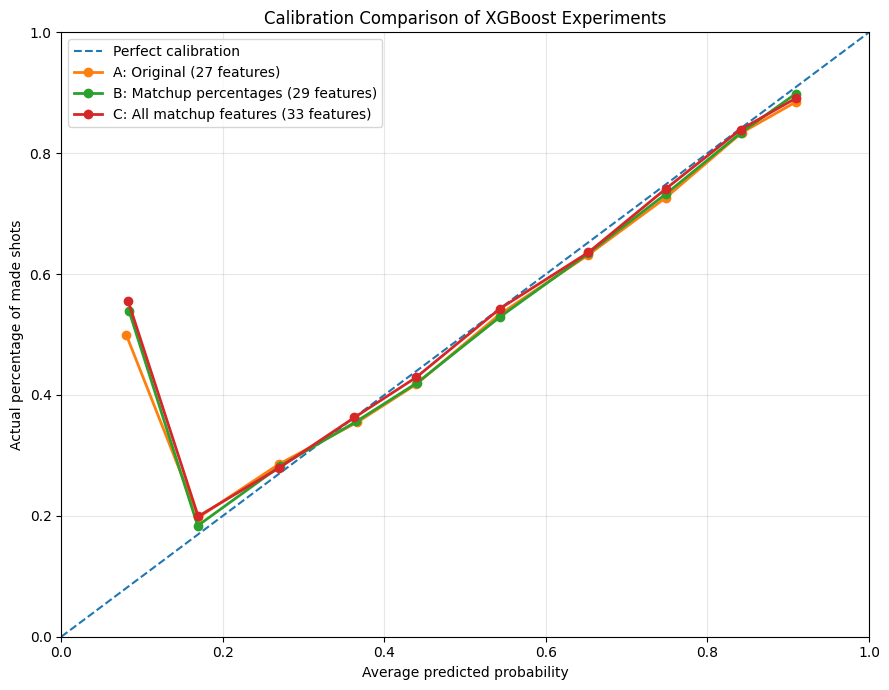

Calibration plot saved successfully.


In [18]:

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np

# Actual validation outcomes
y = validation_data[TARGET].astype(int).to_numpy()

# Define the three models
MODEL_NAMES = [
    "A_original",
    "B_matchup_percentages",
    "C_all_matchup_features"
]

MODEL_LABELS = {
    "A_original": "A: Original (27 features)",
    "B_matchup_percentages": "B: Matchup percentages (29 features)",
    "C_all_matchup_features": "C: All matchup features (33 features)"
}

# Verify predictions
for name in MODEL_NAMES:
    assert name in experiment_predictions
    assert len(experiment_predictions[name]) == len(y)

# Create calibration plot
fig, ax = plt.subplots(figsize=(9, 7))

# Perfect calibration reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

for name in MODEL_NAMES:

    probabilities = experiment_predictions[name]

    # Divide predictions into 10 equal-width groups.
    actual_rates, predicted_rates = calibration_curve(
        y,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    ax.plot(
        predicted_rates,
        actual_rates,
        marker="o",
        linewidth=2,
        label=MODEL_LABELS[name]
    )

ax.set_title("Calibration Comparison of XGBoost Experiments")
ax.set_xlabel("Average predicted probability")
ax.set_ylabel("Actual percentage of made shots")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    REPORT_DIR_EXPERIMENTS / "calibration_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Calibration plot saved successfully.")


In [19]:
# Check how many shots fall into each probability group.

bin_edges = np.linspace(0, 1, 11)

calibration_support = []

for name in MODEL_NAMES:

    probabilities = experiment_predictions[name]

    bin_indices = np.digitize(
        probabilities,
        bin_edges[1:-1]
    )

    for bin_number in range(10):

        mask = bin_indices == bin_number

        if mask.sum() == 0:
            continue

        calibration_support.append({
            "experiment": name,
            "probability_range": (
                f"{bin_edges[bin_number]:.1f}–"
                f"{bin_edges[bin_number + 1]:.1f}"
            ),
            "shots": int(mask.sum()),
            "average_predicted": probabilities[mask].mean(),
            "actual_make_percentage": y[mask].mean()
        })

calibration_support = pd.DataFrame(calibration_support)

display(calibration_support.round(4))

,experiment,probability_range,shots,average_predicted,actual_make_percentage
0,A_original,0.0–0.1,12,0.0803,0.5000
1,A_original,0.1–0.2,223,0.1698,0.1973
2,A_original,0.2–0.3,1649,0.2696,0.2856
3,A_original,0.3–0.4,27370,0.3665,0.3549
4,A_original,0.4–0.5,28964,0.4393,0.4176
5,A_original,0.5–0.6,9191,0.5428,0.5335
6,A_original,0.6–0.7,6548,0.6520,0.6313
7,A_original,0.7–0.8,6571,0.7484,0.7264
8,A_original,0.8–0.9,4243,0.8426,0.8341
9,A_original,0.9–1.0,339,0.9097,0.8850



### Calibration analysis

The calibration curves for all three experiments are broadly similar. However, the model using all six matchup features shows better calibration in several of the larger probability groups.

In particular, the actual make percentages in the 30–40% and 50–60% groups are very close to the average predicted probabilities for Experiment C. This helps explain its lower overall calibration error.

The lowest probability group contains very few shots across all experiments, so its large difference between predicted and actual percentages should be interpreted cautiously.

Overall, adding matchup features appears to improve probability calibration, particularly when all six features are included. However, this improvement does not translate into better ROC-AUC.


In [20]:

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# ------------------------------------------------
# 1. Identify two-point and three-point shots
# ------------------------------------------------

print("Shot types in validation dataset:")
print(validation_data["shot_type"].value_counts())

shot_type = (
    validation_data["shot_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Identify shot type from its label.
two_point_mask = shot_type.str.startswith(("2", "two")).to_numpy()
three_point_mask = shot_type.str.startswith(("3", "three")).to_numpy()

if not two_point_mask.any() or not three_point_mask.any():
    raise ValueError(
        "Could not identify both two-point and three-point shots. "
        "Check the shot types printed above."
    )

# Make sure every validation shot belongs to one of these groups.
classified = two_point_mask | three_point_mask

if not classified.all():
    print("Unclassified shot types:")
    print(validation_data.loc[~classified, "shot_type"].value_counts())
    raise ValueError("Some shot types could not be classified.")

SHOT_GROUPS = {
    "Two-point shots": two_point_mask,
    "Three-point shots": three_point_mask
}

# ------------------------------------------------
# 2. Prepare actual outcomes
# ------------------------------------------------

y_validation = (
    validation_data[TARGET]
    .astype(int)
    .to_numpy()
)

MODEL_NAMES = [
    "A_original",
    "B_matchup_percentages",
    "C_all_matchup_features"
]

# ------------------------------------------------
# 3. Calculate performance for each group
# ------------------------------------------------

subgroup_rows = []

for group_name, mask in SHOT_GROUPS.items():

    y_group = y_validation[mask]

    for model_name in MODEL_NAMES:

        probabilities = np.asarray(
            experiment_predictions[model_name]
        )[mask]

        subgroup_rows.append({

            "shot_group": group_name,

            "experiment": model_name,

            "shots": int(mask.sum()),

            "games": int(
                validation_data.loc[mask, "game_id"].nunique()
            ),

            "actual_make_percentage": (
                y_group.mean() * 100
            ),

            "average_predicted_percentage": (
                probabilities.mean() * 100
            ),

            "log_loss": log_loss(
                y_group,
                probabilities
            ),

            "brier_score": brier_score_loss(
                y_group,
                probabilities
            ),

            "roc_auc": roc_auc_score(
                y_group,
                probabilities
            ),

            "ece": calculate_ece(
                y_group,
                probabilities
            ),

            "calibration_bias": (
                probabilities.mean() - y_group.mean()
            )
        })


# ------------------------------------------------
# 4. Display the results
# ------------------------------------------------

subgroup_results = pd.DataFrame(subgroup_rows)

print("\n" + "=" * 85)
print("TWO-POINT VS THREE-POINT MODEL COMPARISON")
print("=" * 85)

display(
    subgroup_results
    .sort_values(["shot_group", "experiment"])
    .round(6)
)

# ------------------------------------------------
# 5. Save the results
# ------------------------------------------------

subgroup_results.to_csv(
    REPORT_DIR_EXPERIMENTS / "shot_type_model_comparison.csv",
    index=False
)

print("\nResults saved successfully.")


Shot types in validation dataset:
shot_type
2PT Field Goal    49583
3PT Field Goal    35527
Name: count, dtype: Int64



TWO-POINT VS THREE-POINT MODEL COMPARISON


,shot_group,experiment,shots,games,actual_make_percentage,average_predicted_percentage,log_loss,brier_score,roc_auc,ece,calibration_bias
3,Three-point shots,A_original,35527,480,35.879753,37.828102,0.652638,0.230029,0.530461,0.021201,0.019484
4,Three-point shots,B_matchup_percentages,35527,480,35.879753,37.350510,0.652079,0.229773,0.531410,0.016091,0.014708
5,Three-point shots,C_all_matchup_features,35527,480,35.879753,36.741116,0.651876,0.229665,0.530789,0.009884,0.008614
0,Two-point shots,A_original,49583,480,54.920033,56.187553,0.643446,0.226511,0.665173,0.012963,0.012675
1,Two-point shots,B_matchup_percentages,49583,480,54.920033,56.252914,0.643672,0.226659,0.664353,0.013558,0.013329
2,Two-point shots,C_all_matchup_features,49583,480,54.920033,55.115498,0.643828,0.226741,0.662698,0.006239,0.001955



Results saved successfully.



### Two-point and three-point performance

The matchup features showed different results across the two shot types.

For two-point shots, the original 27-feature model performed slightly better in Log Loss, Brier Score and ROC-AUC. However, adding all six matchup features improved calibration, reducing the difference between predicted and actual shooting percentages.

For three-point shots, both matchup experiments improved Log Loss, Brier Score and calibration compared with the original model. The changes in ROC-AUC were very small, and all three models showed relatively limited ability to distinguish made from missed three-point shots.

Overall, the matchup features appear to provide more value for three-point predictions and probability calibration than for two-point shot discrimination. These findings are exploratory and require further validation.


## Stage 7: Game-level comparison by shot type

We separately compare the three XGBoost experiments on two-point and three-point shots.

A paired game-level bootstrap is used to estimate the uncertainty in the differences between models.

We repeatedly sample validation games with replacement. All shots from a selected game are kept together, and the same sampled games are used for every model.

This helps us understand whether the matchup features provide consistent improvements for either type of shot.

The reserved test dataset remains untouched.

In [21]:

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# ------------------------------------------------
# 1. Set up the validation data
# ------------------------------------------------

y = validation_data[TARGET].astype(int).to_numpy()

shot_type = (
    validation_data["shot_type"]
    .astype(str)
    .str.strip()
    .str.upper()
)

SHOT_GROUPS = {
    "Two-point shots": shot_type.str.startswith("2PT").to_numpy(),
    "Three-point shots": shot_type.str.startswith("3PT").to_numpy()
}

MODEL_NAMES = [
    "A_original",
    "B_matchup_percentages",
    "C_all_matchup_features"
]

BASELINE = "A_original"

CANDIDATES = [
    "B_matchup_percentages",
    "C_all_matchup_features"
]

for group_name, mask in SHOT_GROUPS.items():
    assert mask.sum() > 0, f"No shots found for {group_name}"

for name in MODEL_NAMES:
    assert len(experiment_predictions[name]) == len(y)

# ------------------------------------------------
# 2. Identify the validation games
# ------------------------------------------------

game_ids = validation_data["game_id"].astype(str).to_numpy()

unique_games, game_codes = np.unique(
    game_ids,
    return_inverse=True
)

N_GAMES = len(unique_games)

print("Validation games:", N_GAMES)
print("Two-point shots:", SHOT_GROUPS["Two-point shots"].sum())
print("Three-point shots:", SHOT_GROUPS["Three-point shots"].sum())

assert N_GAMES == 480

# ------------------------------------------------
# 3. Define evaluation metrics
# ------------------------------------------------

def weighted_ece(y_true, probabilities, weights, bins=10):

    edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.minimum(
        np.digitize(probabilities, edges[1:-1]),
        bins - 1
    )

    total_weight = weights.sum()
    ece = 0.0

    for bin_number in range(bins):

        mask = (
            (bin_indices == bin_number)
            & (weights > 0)
        )

        if not mask.any():
            continue

        bin_weights = weights[mask]

        actual_rate = np.average(
            y_true[mask],
            weights=bin_weights
        )

        predicted_rate = np.average(
            probabilities[mask],
            weights=bin_weights
        )

        ece += (
            bin_weights.sum() / total_weight
            * abs(actual_rate - predicted_rate)
        )

    return float(ece)


def calculate_metrics(y_true, probabilities, weights):

    return {
        "log_loss": log_loss(
            y_true,
            probabilities,
            sample_weight=weights,
            labels=[0, 1]
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities,
            sample_weight=weights
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
            sample_weight=weights
        ),

        "ece": weighted_ece(
            y_true,
            probabilities,
            weights
        ),

        "absolute_calibration_bias": abs(
            np.average(
                probabilities - y_true,
                weights=weights
            )
        )
    }


# ------------------------------------------------
# 4. Define which direction is better
# ------------------------------------------------

LOWER_IS_BETTER = [
    "log_loss",
    "brier_score",
    "ece",
    "absolute_calibration_bias"
]

HIGHER_IS_BETTER = ["roc_auc"]

METRICS = LOWER_IS_BETTER + HIGHER_IS_BETTER

# ------------------------------------------------
# 5. Run paired bootstrap separately by shot type
# ------------------------------------------------

N_BOOTSTRAPS = 1000
SEED = 20261124

rng = np.random.default_rng(SEED)

bootstrap_records = []

for group_name, group_mask in SHOT_GROUPS.items():

    print("\n" + "=" * 65)
    print("ANALYZING:", group_name)
    print("=" * 65)

    y_group = y[group_mask]

    group_game_codes = game_codes[group_mask]

    group_predictions = {
        name: np.asarray(experiment_predictions[name])[group_mask]
        for name in MODEL_NAMES
    }

    group_scores = {
        name: calculate_metrics(
            y_group,
            group_predictions[name],
            np.ones(len(y_group))
        )
        for name in MODEL_NAMES
    }

    print("Shots:", len(y_group))
    print("Games:", len(np.unique(group_game_codes)))

    # Store bootstrap improvements for each comparison.
    improvements = {
        (candidate, metric): []
        for candidate in CANDIDATES
        for metric in METRICS
    }

    for iteration in range(N_BOOTSTRAPS):

        # Sample the same 480 games for all models.
        sampled_games = rng.integers(
            low=0,
            high=N_GAMES,
            size=N_GAMES
        )

        # Count how often each game was selected.
        game_weights = np.bincount(
            sampled_games,
            minlength=N_GAMES
        )

        # Assign each shot the weight of its game.
        shot_weights = game_weights[group_game_codes].astype(float)

        # Evaluate all three models on the same sample.
        sampled_scores = {
            name: calculate_metrics(
                y_group,
                group_predictions[name],
                shot_weights
            )
            for name in MODEL_NAMES
        }

        baseline_scores = sampled_scores[BASELINE]

        # Calculate improvement over the original model.
        for candidate in CANDIDATES:

            candidate_scores = sampled_scores[candidate]

            for metric in LOWER_IS_BETTER:

                improvement = (
                    baseline_scores[metric]
                    - candidate_scores[metric]
                )

                improvements[(candidate, metric)].append(improvement)

            for metric in HIGHER_IS_BETTER:

                improvement = (
                    candidate_scores[metric]
                    - baseline_scores[metric]
                )

                improvements[(candidate, metric)].append(improvement)

        if (iteration + 1) % 200 == 0:
            print(
                f"Completed {iteration + 1}/{N_BOOTSTRAPS} samples."
            )

    # ------------------------------------------------
    # 6. Summarize results for this shot type
    # ------------------------------------------------

    for candidate in CANDIDATES:

        for metric in METRICS:

            values = np.asarray(
                improvements[(candidate, metric)]
            )

            lower, upper = np.percentile(
                values,
                [2.5, 97.5]
            )

            point_improvement = (
                group_scores[BASELINE][metric]
                - group_scores[candidate][metric]
                if metric in LOWER_IS_BETTER
                else
                group_scores[candidate][metric]
                - group_scores[BASELINE][metric]
            )

            bootstrap_records.append({

                "shot_group": group_name,

                "candidate": candidate,

                "metric": metric,

                "baseline_score": group_scores[BASELINE][metric],

                "candidate_score": group_scores[candidate][metric],

                "point_improvement": point_improvement,

                "ci_lower_95": lower,

                "ci_upper_95": upper,

                "bootstrap_samples_favoring_candidate_pct": (
                    (values > 0).mean() * 100
                )

            })


# ------------------------------------------------
# 7. Display final results
# ------------------------------------------------

shot_bootstrap_results = pd.DataFrame(bootstrap_records)

print("\n" + "=" * 90)
print("PAIRED BOOTSTRAP: TWO-POINT AND THREE-POINT SHOTS")
print("=" * 90)

display(
    shot_bootstrap_results
    .sort_values(["shot_group", "candidate", "metric"])
    .round(7)
)

# ------------------------------------------------
# 8. Save results
# ------------------------------------------------

OUTPUT_FILE = (
    REPORT_DIR_EXPERIMENTS
    / "shot_type_paired_bootstrap_results.csv"
)

shot_bootstrap_results.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nResults saved to:", OUTPUT_FILE)
print("Shot-type bootstrap analysis completed.")


Validation games: 480
Two-point shots: 49583
Three-point shots: 35527

ANALYZING: Two-point shots
Shots: 49583
Games: 480
Completed 200/1000 samples.
Completed 400/1000 samples.
Completed 600/1000 samples.
Completed 800/1000 samples.
Completed 1000/1000 samples.

ANALYZING: Three-point shots
Shots: 35527
Games: 480
Completed 200/1000 samples.
Completed 400/1000 samples.
Completed 600/1000 samples.
Completed 800/1000 samples.
Completed 1000/1000 samples.

PAIRED BOOTSTRAP: TWO-POINT AND THREE-POINT SHOTS


,shot_group,candidate,metric,baseline_score,candidate_score,point_improvement,ci_lower_95,ci_upper_95,bootstrap_samples_favoring_candidate_pct
13,Three-point shots,B_matchup_percentages,absolute_calibration_bias,0.019484,0.014708,0.004776,0.004241,0.005275,100.0
11,Three-point shots,B_matchup_percentages,brier_score,0.230029,0.229773,0.000256,0.000059,0.000448,99.4
12,Three-point shots,B_matchup_percentages,ece,0.021201,0.016091,0.005110,0.003596,0.006580,100.0
10,Three-point shots,B_matchup_percentages,log_loss,0.652638,0.652079,0.000559,0.000134,0.000975,99.5
14,Three-point shots,B_matchup_percentages,roc_auc,0.530462,0.531410,0.000948,-0.002164,0.003753,71.9
18,Three-point shots,C_all_matchup_features,absolute_calibration_bias,0.019484,0.008614,0.010870,0.009750,0.012043,100.0
16,Three-point shots,C_all_matchup_features,brier_score,0.230029,0.229665,0.000363,0.000086,0.000635,99.2
17,Three-point shots,C_all_matchup_features,ece,0.021201,0.009884,0.011317,0.008320,0.013045,100.0
15,Three-point shots,C_all_matchup_features,log_loss,0.652638,0.651876,0.000762,0.000171,0.001339,99.1
19,Three-point shots,C_all_matchup_features,roc_auc,0.530462,0.530789,0.000327,-0.003991,0.004706,55.2



Results saved to: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_experiments\shot_type_paired_bootstrap_results.csv
Shot-type bootstrap analysis completed.



### Findings from two-point and three-point bootstrap comparisons

The paired game-level bootstrap revealed different results for two-point and three-point shots.

For three-point shots, both matchup experiments showed consistent improvements in Log Loss, Brier Score and calibration compared with the original model. The 95% confidence intervals for these improvements were entirely above zero. However, neither experiment showed a clear improvement in ROC-AUC.

For two-point shots, the matchup features did not improve overall prediction performance. The original model remained stronger in shot discrimination. Adding all six matchup features improved absolute calibration bias, but also produced a decline in ROC-AUC.

Overall, the new matchup features appear to provide more value for three-point shot probability estimation than for two-point shot prediction. Their contribution is more apparent in probability calibration than in distinguishing made shots from missed shots.


## Stage 8: Final evaluation on the test dataset

We now evaluate the three finalized XGBoost experiments on the reserved test dataset.

Each model is retrained using the combined training and validation data, with the same XGBoost settings used in the earlier experiments.

The test dataset is used only for final evaluation. We do not use its results to change model settings or select new features.

We compare overall performance and separately examine two-point and three-point shots.

A paired game-level bootstrap is also used to estimate uncertainty in the differences between models.

In [22]:

import time
import json
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# ============================================================
# 1. PREPARE FINAL TRAINING AND TEST DATA
# ============================================================

TARGET = "shot_made_flag"

# Use training + validation for final model fitting.
final_train_data = modeling_data.loc[
    modeling_data["split"].isin(["train", "validation"])
].copy()

# Keep the reserved test data separate.
final_test_data = modeling_data.loc[
    modeling_data["split"] == "test"
].copy()

print("Final training + validation shots:", len(final_train_data))
print("Reserved test shots:", len(final_test_data))

print("Training games:",
      final_train_data["game_id"].nunique())

print("Test games:",
      final_test_data["game_id"].nunique())

# Verify expected sizes.
assert len(final_train_data) == 425398
assert len(final_test_data) == 42139

assert final_train_data["game_id"].nunique() == 2389
assert final_test_data["game_id"].nunique() == 240

# Verify that no game appears in both datasets.
assert set(final_train_data["game_id"]).isdisjoint(
    set(final_test_data["game_id"])
)

# Verify chronological order.
assert (
    final_train_data["game_date"].max()
    < final_test_data["game_date"].min()
)

# Verify targets.
assert final_train_data[TARGET].notna().all()
assert final_test_data[TARGET].notna().all()

y_final_train = (
    final_train_data[TARGET].astype(int).to_numpy()
)

y_test = (
    final_test_data[TARGET].astype(int).to_numpy()
)

print("\nFinal training make percentage:",
      round(y_final_train.mean() * 100, 2), "%")

print("Test make percentage:",
      round(y_test.mean() * 100, 2), "%")


# ============================================================
# 2. DEFINE THE SAME MODEL SETTINGS
# ============================================================

FINAL_XGB_PARAMS = {
    "n_estimators": 400,
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "n_jobs": 4,
    "random_state": 42,
    "verbosity": 0
}

CATEGORICAL_CANDIDATES = [
    "shot_type",
    "shot_zone_basic",
    "shot_zone_area",
    "season"
]


# ============================================================
# 3. BUILD THE XGBOOST PIPELINE
# ============================================================

def build_final_pipeline(features):

    categorical_features = [
        col for col in CATEGORICAL_CANDIDATES
        if col in features
    ]

    numerical_features = [
        col for col in features
        if col not in categorical_features
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            (
                "numerical",
                "passthrough",
                numerical_features
            )
        ],
        remainder="drop"
    )

    model = xgb.XGBClassifier(**FINAL_XGB_PARAMS)

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])


# ============================================================
# 4. CREATE OUTPUT FOLDERS
# ============================================================

FINAL_MODEL_DIR = (
    ROOT / "models" / "matchup_experiments_final"
)

FINAL_REPORT_DIR = (
    ROOT / "reports" / "matchup_experiments_final"
)

FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
FINAL_REPORT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 5. FIT THE THREE FINAL MODELS
# ============================================================

final_models = {}
final_predictions = {}
training_time_rows = []

for experiment_name, features in FEATURE_CONFIGURATIONS.items():

    print("\n" + "=" * 70)
    print("FINAL MODEL:", experiment_name)
    print("Number of features:", len(features))
    print("=" * 70)

    X_train_final = final_train_data[features].copy()
    X_test_final = final_test_data[features].copy()

    # Convert categorical features to strings.
    for col in CATEGORICAL_CANDIDATES:
        if col in features:
            X_train_final[col] = X_train_final[col].astype(str)
            X_test_final[col] = X_test_final[col].astype(str)

    numerical_features = [
        col for col in features
        if col not in CATEGORICAL_CANDIDATES
    ]

    X_train_final[numerical_features] = (
        X_train_final[numerical_features].astype("float32")
    )

    X_test_final[numerical_features] = (
        X_test_final[numerical_features].astype("float32")
    )

    pipeline = build_final_pipeline(features)

    start_time = time.time()

    pipeline.fit(
        X_train_final,
        y_final_train
    )

    fit_seconds = time.time() - start_time

    print(f"Training completed in {fit_seconds:.2f} seconds.")

    # Test predictions are generated only after fitting is complete.
    probabilities = pipeline.predict_proba(
        X_test_final
    )[:, 1]

    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    final_models[experiment_name] = pipeline
    final_predictions[experiment_name] = probabilities

    # Save each final model separately.
    model_path = (
        FINAL_MODEL_DIR / f"{experiment_name}_final.joblib"
    )

    joblib.dump(
        {
            "pipeline": pipeline,
            "features": features,
            "target": TARGET,
            "xgboost_parameters": FINAL_XGB_PARAMS,
            "experiment": experiment_name
        },
        model_path,
        compress=3
    )

    training_time_rows.append({
        "experiment": experiment_name,
        "features": len(features),
        "training_seconds": fit_seconds,
        "model_path": str(model_path)
    })

    print("Saved:", model_path)


# ============================================================
# 6. DEFINE EVALUATION METRICS
# ============================================================

def final_ece(y_true, probabilities, bins=10):

    edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.minimum(
        np.digitize(probabilities, edges[1:-1]),
        bins - 1
    )

    ece = 0.0

    for bin_number in range(bins):

        mask = bin_indices == bin_number

        if not mask.any():
            continue

        actual = y_true[mask].mean()
        predicted = probabilities[mask].mean()

        ece += mask.mean() * abs(actual - predicted)

    return float(ece)


def final_metrics(y_true, probabilities):

    return {
        "log_loss": log_loss(
            y_true,
            probabilities,
            labels=[0, 1]
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "ece": final_ece(
            y_true,
            probabilities
        ),

        "calibration_bias": (
            probabilities.mean() - y_true.mean()
        )
    }


# ============================================================
# 7. OVERALL TEST PERFORMANCE
# ============================================================

overall_rows = []

for experiment_name, probabilities in final_predictions.items():

    overall_rows.append({

        "experiment": experiment_name,

        "features": len(
            FEATURE_CONFIGURATIONS[experiment_name]
        ),

        "shots": len(y_test),

        "actual_make_percentage": y_test.mean() * 100,

        "average_predicted_percentage": (
            probabilities.mean() * 100
        ),

        **final_metrics(y_test, probabilities)

    })


final_overall_results = pd.DataFrame(overall_rows)

final_overall_results = final_overall_results.sort_values(
    "log_loss"
).reset_index(drop=True)

print("\n" + "=" * 85)
print("FINAL TEST RESULTS: ALL SHOTS")
print("=" * 85)

display(final_overall_results.round(6))


# ============================================================
# 8. TWO-POINT AND THREE-POINT TEST PERFORMANCE
# ============================================================

test_shot_types = (
    final_test_data["shot_type"]
    .astype(str)
    .str.strip()
    .str.upper()
)

test_shot_groups = {
    "Two-point shots": test_shot_types.str.startswith("2PT").to_numpy(),
    "Three-point shots": test_shot_types.str.startswith("3PT").to_numpy()
}

subgroup_rows = []

for group_name, mask in test_shot_groups.items():

    y_group = y_test[mask]

    for experiment_name, probabilities in final_predictions.items():

        group_probabilities = probabilities[mask]

        subgroup_rows.append({

            "shot_group": group_name,

            "experiment": experiment_name,

            "shots": int(mask.sum()),

            "actual_make_percentage": y_group.mean() * 100,

            "average_predicted_percentage": (
                group_probabilities.mean() * 100
            ),

            **final_metrics(y_group, group_probabilities)

        })


final_subgroup_results = pd.DataFrame(subgroup_rows)

print("\n" + "=" * 85)
print("FINAL TEST RESULTS: TWO-POINT AND THREE-POINT SHOTS")
print("=" * 85)

display(
    final_subgroup_results
    .sort_values(["shot_group", "experiment"])
    .round(6)
)


# ============================================================
# 9. PAIRED GAME-LEVEL BOOTSTRAP ON TEST DATA
# ============================================================

test_game_ids = (
    final_test_data["game_id"].astype(str).to_numpy()
)

unique_test_games, test_game_codes = np.unique(
    test_game_ids,
    return_inverse=True
)

N_TEST_GAMES = len(unique_test_games)

assert N_TEST_GAMES == 240

def weighted_final_ece(y_true, probabilities, weights, bins=10):

    edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.minimum(
        np.digitize(probabilities, edges[1:-1]),
        bins - 1
    )

    total_weight = weights.sum()
    ece = 0.0

    for bin_number in range(bins):

        mask = (
            (bin_indices == bin_number)
            & (weights > 0)
        )

        if not mask.any():
            continue

        actual = np.average(
            y_true[mask],
            weights=weights[mask]
        )

        predicted = np.average(
            probabilities[mask],
            weights=weights[mask]
        )

        ece += (
            weights[mask].sum() / total_weight
            * abs(actual - predicted)
        )

    return float(ece)


def weighted_final_metrics(y_true, probabilities, weights):

    active = weights > 0

    y_active = y_true[active]
    p_active = probabilities[active]
    w_active = weights[active]

    return {
        "log_loss": log_loss(
            y_active,
            p_active,
            sample_weight=w_active,
            labels=[0, 1]
        ),

        "brier_score": brier_score_loss(
            y_active,
            p_active,
            sample_weight=w_active
        ),

        "roc_auc": (
            roc_auc_score(
                y_active,
                p_active,
                sample_weight=w_active
            )
            if len(np.unique(y_active)) == 2
            else np.nan
        ),

        "ece": weighted_final_ece(
            y_active,
            p_active,
            w_active
        ),

        "absolute_calibration_bias": abs(
            np.average(
                p_active - y_active,
                weights=w_active
            )
        )
    }


# Use the same sampled test games for every comparison.
N_BOOTSTRAPS = 1000
BOOTSTRAP_SEED = 20261125

rng = np.random.default_rng(BOOTSTRAP_SEED)

BASELINE = "A_original"

CANDIDATES = [
    "B_matchup_percentages",
    "C_all_matchup_features"
]

LOWER_IS_BETTER = [
    "log_loss",
    "brier_score",
    "ece",
    "absolute_calibration_bias"
]

HIGHER_IS_BETTER = ["roc_auc"]

METRICS = LOWER_IS_BETTER + HIGHER_IS_BETTER

BOOTSTRAP_GROUPS = {
    "All shots": np.ones(len(y_test), dtype=bool),
    **test_shot_groups
}

bootstrap_rows = []

for group_name, group_mask in BOOTSTRAP_GROUPS.items():

    print("\nBootstrap:", group_name)

    y_group = y_test[group_mask]

    group_game_codes = test_game_codes[group_mask]

    group_predictions = {
        name: final_predictions[name][group_mask]
        for name in final_predictions
    }

    # Exact point estimates for this group.
    point_scores = {
        name: final_metrics(
            y_group,
            group_predictions[name]
        )
        for name in final_predictions
    }

    improvements = {
        (candidate, metric): []
        for candidate in CANDIDATES
        for metric in METRICS
    }

    for iteration in range(N_BOOTSTRAPS):

        sampled_games = rng.integers(
            0,
            N_TEST_GAMES,
            size=N_TEST_GAMES
        )

        game_multiplicities = np.bincount(
            sampled_games,
            minlength=N_TEST_GAMES
        )

        shot_weights = (
            game_multiplicities[group_game_codes]
            .astype(float)
        )

        sampled_scores = {
            name: weighted_final_metrics(
                y_group,
                group_predictions[name],
                shot_weights
            )
            for name in final_predictions
        }

        baseline_scores = sampled_scores[BASELINE]

        for candidate in CANDIDATES:

            candidate_scores = sampled_scores[candidate]

            for metric in METRICS:

                if metric in LOWER_IS_BETTER:

                    improvement = (
                        baseline_scores[metric]
                        - candidate_scores[metric]
                    )

                else:

                    improvement = (
                        candidate_scores[metric]
                        - baseline_scores[metric]
                    )

                improvements[(candidate, metric)].append(
                    improvement
                )

        if (iteration + 1) % 200 == 0:
            print(
                f"Completed {iteration + 1}/{N_BOOTSTRAPS}"
            )

    for candidate in CANDIDATES:

        for metric in METRICS:

            values = np.asarray(
                improvements[(candidate, metric)]
            )

            values = values[np.isfinite(values)]

            lower, upper = np.percentile(
                values,
                [2.5, 97.5]
            )

            if metric in LOWER_IS_BETTER:

                point_improvement = (
                    point_scores[BASELINE][metric]
                    - point_scores[candidate][metric]
                )

            else:

                point_improvement = (
                    point_scores[candidate][metric]
                    - point_scores[BASELINE][metric]
                )

            bootstrap_rows.append({

                "shot_group": group_name,

                "candidate": candidate,

                "metric": metric,

                "point_improvement": point_improvement,

                "ci_lower_95": lower,

                "ci_upper_95": upper,

                "bootstrap_samples_favoring_candidate_pct": (
                    (values > 0).mean() * 100
                ),

                "finite_bootstrap_samples": len(values)

            })


final_bootstrap_results = pd.DataFrame(bootstrap_rows)

print("\n" + "=" * 90)
print("FINAL TEST: PAIRED GAME-LEVEL BOOTSTRAP")
print("=" * 90)

display(
    final_bootstrap_results
    .sort_values(["shot_group", "candidate", "metric"])
    .round(7)
)


# ============================================================
# 10. SAVE ALL FINAL RESULTS
# ============================================================

final_overall_results.to_csv(
    FINAL_REPORT_DIR / "final_test_overall_results.csv",
    index=False
)

final_subgroup_results.to_csv(
    FINAL_REPORT_DIR / "final_test_shot_type_results.csv",
    index=False
)

final_bootstrap_results.to_csv(
    FINAL_REPORT_DIR / "final_test_bootstrap_results.csv",
    index=False
)

pd.DataFrame(training_time_rows).to_csv(
    FINAL_REPORT_DIR / "final_training_times.csv",
    index=False
)

# Save test predictions for later reporting.
final_prediction_output = final_test_data[
    KEYS + ["game_date", "shot_type", TARGET]
].copy()

for experiment_name, probabilities in final_predictions.items():
    final_prediction_output[experiment_name] = probabilities

final_prediction_output.to_parquet(
    FINAL_REPORT_DIR / "final_test_predictions.parquet",
    index=False
)

# Save the experiment configuration and final settings.
final_manifest = {
    "training_shots": len(final_train_data),
    "training_games": int(final_train_data["game_id"].nunique()),
    "test_shots": len(final_test_data),
    "test_games": N_TEST_GAMES,
    "test_period_start": str(final_test_data["game_date"].min()),
    "test_period_end": str(final_test_data["game_date"].max()),
    "xgboost_parameters": FINAL_XGB_PARAMS,
    "experiments": {
        name: features
        for name, features in FEATURE_CONFIGURATIONS.items()
    },
    "test_used_for_model_selection": False,
    "bootstrap_replicates": N_BOOTSTRAPS
}

with open(
    FINAL_REPORT_DIR / "final_test_manifest.json",
    "w"
) as file:
    json.dump(final_manifest, file, indent=2)

print("\n" + "=" * 80)
print("FINAL TEST EVALUATION COMPLETED")
print("=" * 80)

print("Models saved to:", FINAL_MODEL_DIR)
print("Reports saved to:", FINAL_REPORT_DIR)
print("Test shots evaluated:", len(final_test_data))
print("Test games evaluated:", N_TEST_GAMES)
print("Test data used for tuning: No")


Final training + validation shots: 425398
Reserved test shots: 42139
Training games: 2389
Test games: 240

Final training make percentage: 46.79 %
Test make percentage: 47.09 %

FINAL MODEL: A_original
Number of features: 27
Training completed in 9.05 seconds.
Saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments_final\A_original_final.joblib

FINAL MODEL: B_matchup_percentages
Number of features: 29
Training completed in 9.10 seconds.
Saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments_final\B_matchup_percentages_final.joblib

FINAL MODEL: C_all_matchup_features
Number of features: 33
Training completed in 9.05 seconds.
Saved: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\models\matchup_experiments_final\C_all_matchup_features_final.joblib

FINAL TEST RESULTS: ALL SHOTS


,experiment,features,shots,actual_make_percentage,average_predicted_percentage,log_loss,brier_score,roc_auc,ece,calibration_bias
0,B_matchup_percentages,29,42139,47.087022,47.027649,0.644470,0.226761,0.657332,0.008192,-0.000594
1,A_original,27,42139,47.087022,47.177246,0.644732,0.226899,0.656509,0.009533,0.000902
2,C_all_matchup_features,33,42139,47.087022,47.197769,0.645027,0.227008,0.656687,0.010847,0.001107



FINAL TEST RESULTS: TWO-POINT AND THREE-POINT SHOTS


,shot_group,experiment,shots,actual_make_percentage,average_predicted_percentage,log_loss,brier_score,roc_auc,ece,calibration_bias
3,Three-point shots,A_original,17252,36.001623,35.482399,0.651695,0.229593,0.536183,0.008793,-0.005192
4,Three-point shots,B_matchup_percentages,17252,36.001623,35.427757,0.651407,0.229441,0.538933,0.006865,-0.005739
5,Three-point shots,C_all_matchup_features,17252,36.001623,35.613171,0.652131,0.229764,0.537530,0.012124,-0.003885
0,Two-point shots,A_original,24887,54.771567,55.284275,0.639904,0.225032,0.669276,0.010068,0.005127
1,Two-point shots,B_matchup_percentages,24887,54.771567,55.068844,0.639660,0.224904,0.669805,0.009316,0.002973
2,Two-point shots,C_all_matchup_features,24887,54.771567,55.228363,0.640101,0.225099,0.669314,0.010528,0.004568



Bootstrap: All shots
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000


KeyError: 'absolute_calibration_bias'

In [23]:

# ============================================================
# CORRECTED FINAL TEST: PAIRED GAME-LEVEL BOOTSTRAP
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

# Metrics where lower is better.
LOWER_IS_BETTER = [
    "log_loss",
    "brier_score",
    "ece",
    "absolute_calibration_bias"
]

# Metrics where higher is better.
HIGHER_IS_BETTER = ["roc_auc"]
METRICS = LOWER_IS_BETTER + HIGHER_IS_BETTER

BASELINE = "A_original"
CANDIDATES = [
    "B_matchup_percentages",
    "C_all_matchup_features"
]

# ------------------------------------------------
# 1. Corrected weighted evaluation functions
# ------------------------------------------------

def weighted_final_ece(y_true, probabilities, weights, bins=10):

    edges = np.linspace(0, 1, bins + 1)

    bin_indices = np.minimum(
        np.digitize(probabilities, edges[1:-1]),
        bins - 1
    )

    total_weight = weights.sum()
    ece = 0.0

    for bin_number in range(bins):

        mask = (
            (bin_indices == bin_number)
            & (weights > 0)
        )

        if not mask.any():
            continue

        actual = np.average(
            y_true[mask],
            weights=weights[mask]
        )

        predicted = np.average(
            probabilities[mask],
            weights=weights[mask]
        )

        ece += (
            weights[mask].sum() / total_weight
            * abs(actual - predicted)
        )

    return float(ece)


def weighted_final_metrics(y_true, probabilities, weights):

    active = weights > 0

    y_active = y_true[active]
    p_active = probabilities[active]
    w_active = weights[active]

    signed_bias = np.average(
        p_active - y_active,
        weights=w_active
    )

    return {
        "log_loss": log_loss(
            y_active,
            p_active,
            sample_weight=w_active,
            labels=[0, 1]
        ),

        "brier_score": brier_score_loss(
            y_active,
            p_active,
            sample_weight=w_active
        ),

        "roc_auc": (
            roc_auc_score(
                y_active,
                p_active,
                sample_weight=w_active
            )
            if len(np.unique(y_active)) == 2
            else np.nan
        ),

        "ece": weighted_final_ece(
            y_active,
            p_active,
            w_active
        ),

        "absolute_calibration_bias": abs(signed_bias)
    }


# ------------------------------------------------
# 2. Verify existing test predictions
# ------------------------------------------------

y = y_test

for name in [BASELINE] + CANDIDATES:
    assert name in final_predictions
    assert len(final_predictions[name]) == len(y)

print("Test shots:", len(y))
print("Test games:", N_TEST_GAMES)
print("All three saved model predictions are available.")


# ------------------------------------------------
# 3. Prepare the three evaluation groups
# ------------------------------------------------

BOOTSTRAP_GROUPS = {
    "All shots": np.ones(len(y), dtype=bool),
    **test_shot_groups
}

N_BOOTSTRAPS = 1000
rng = np.random.default_rng(20261125)

bootstrap_rows = []


# ------------------------------------------------
# 4. Run paired game-level bootstrap
# ------------------------------------------------

for group_name, group_mask in BOOTSTRAP_GROUPS.items():

    print("\nAnalyzing:", group_name)

    y_group = y[group_mask]

    group_game_codes = test_game_codes[group_mask]

    group_predictions = {
        name: np.asarray(final_predictions[name])[group_mask]
        for name in [BASELINE] + CANDIDATES
    }

    # Point estimates use the same corrected metric function.
    point_scores = {
        name: weighted_final_metrics(
            y_group,
            probabilities,
            np.ones(len(y_group))
        )
        for name, probabilities in group_predictions.items()
    }

    improvements = {
        (candidate, metric): []
        for candidate in CANDIDATES
        for metric in METRICS
    }

    for iteration in range(N_BOOTSTRAPS):

        sampled_games = rng.integers(
            0,
            N_TEST_GAMES,
            size=N_TEST_GAMES
        )

        game_multiplicities = np.bincount(
            sampled_games,
            minlength=N_TEST_GAMES
        )

        shot_weights = (
            game_multiplicities[group_game_codes]
            .astype(float)
        )

        sampled_scores = {
            name: weighted_final_metrics(
                y_group,
                probabilities,
                shot_weights
            )
            for name, probabilities in group_predictions.items()
        }

        baseline_scores = sampled_scores[BASELINE]

        for candidate in CANDIDATES:

            candidate_scores = sampled_scores[candidate]

            for metric in METRICS:

                if metric in LOWER_IS_BETTER:
                    improvement = (
                        baseline_scores[metric]
                        - candidate_scores[metric]
                    )
                else:
                    improvement = (
                        candidate_scores[metric]
                        - baseline_scores[metric]
                    )

                improvements[(candidate, metric)].append(improvement)

        if (iteration + 1) % 200 == 0:
            print(f"Completed {iteration + 1}/{N_BOOTSTRAPS}")


    # ------------------------------------------------
    # 5. Calculate confidence intervals
    # ------------------------------------------------

    for candidate in CANDIDATES:

        for metric in METRICS:

            values = np.asarray(
                improvements[(candidate, metric)]
            )

            values = values[np.isfinite(values)]

            lower, upper = np.percentile(
                values,
                [2.5, 97.5]
            )

            if metric in LOWER_IS_BETTER:
                point_improvement = (
                    point_scores[BASELINE][metric]
                    - point_scores[candidate][metric]
                )
            else:
                point_improvement = (
                    point_scores[candidate][metric]
                    - point_scores[BASELINE][metric]
                )

            bootstrap_rows.append({

                "shot_group": group_name,
                "candidate": candidate,
                "metric": metric,
                "baseline_score": point_scores[BASELINE][metric],
                "candidate_score": point_scores[candidate][metric],
                "point_improvement": point_improvement,
                "ci_lower_95": lower,
                "ci_upper_95": upper,
                "bootstrap_samples_favoring_candidate_pct": (
                    (values > 0).mean() * 100
                ),
                "finite_bootstrap_samples": len(values)

            })


# ------------------------------------------------
# 6. Display final results
# ------------------------------------------------

final_bootstrap_results = pd.DataFrame(bootstrap_rows)

print("\n" + "=" * 85)
print("FINAL TEST: PAIRED GAME-LEVEL BOOTSTRAP")
print("=" * 85)

display(
    final_bootstrap_results
    .sort_values(["shot_group", "candidate", "metric"])
    .round(7)
)

# Save bootstrap results.
final_bootstrap_results.to_csv(
    FINAL_REPORT_DIR / "final_test_bootstrap_results.csv",
    index=False
)

print("\nBootstrap results saved successfully.")


Test shots: 42139
Test games: 240
All three saved model predictions are available.

Analyzing: All shots
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000

Analyzing: Two-point shots
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000

Analyzing: Three-point shots
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000

FINAL TEST: PAIRED GAME-LEVEL BOOTSTRAP


,shot_group,candidate,metric,baseline_score,candidate_score,point_improvement,ci_lower_95,ci_upper_95,bootstrap_samples_favoring_candidate_pct,finite_bootstrap_samples
3,All shots,B_matchup_percentages,absolute_calibration_bias,0.000902,0.000594,0.000309,-0.001864,0.001937,51.6,1000
1,All shots,B_matchup_percentages,brier_score,0.226899,0.226761,0.000138,-0.000045,0.000318,92.9,1000
2,All shots,B_matchup_percentages,ece,0.009533,0.008192,0.001341,-0.001228,0.004281,86.4,1000
0,All shots,B_matchup_percentages,log_loss,0.644732,0.644470,0.000262,-0.000134,0.000665,89.0,1000
4,All shots,B_matchup_percentages,roc_auc,0.656509,0.657332,0.000823,-0.000146,0.001809,95.2,1000
8,All shots,C_all_matchup_features,absolute_calibration_bias,0.000902,0.001107,-0.000205,-0.001069,0.000912,39.9,1000
6,All shots,C_all_matchup_features,brier_score,0.226899,0.227009,-0.000109,-0.000358,0.000133,19.8,1000
7,All shots,C_all_matchup_features,ece,0.009533,0.010847,-0.001314,-0.004543,0.003048,32.3,1000
5,All shots,C_all_matchup_features,log_loss,0.644732,0.645027,-0.000295,-0.000837,0.000240,15.0,1000
9,All shots,C_all_matchup_features,roc_auc,0.656509,0.656687,0.000178,-0.001199,0.001608,59.7,1000



Bootstrap results saved successfully.


In [24]:
# Save overall and shot-type results.
final_overall_results.to_csv(
    FINAL_REPORT_DIR / "final_test_overall_results.csv",
    index=False
)

final_subgroup_results.to_csv(
    FINAL_REPORT_DIR / "final_test_shot_type_results.csv",
    index=False
)

# Save predictions.
final_prediction_output = final_test_data[
    KEYS + ["game_date", "shot_type", TARGET]
].copy()

for name, probabilities in final_predictions.items():
    final_prediction_output[name] = probabilities

final_prediction_output.to_parquet(
    FINAL_REPORT_DIR / "final_test_predictions.parquet",
    index=False
)

# Save training times.
pd.DataFrame(training_time_rows).to_csv(
    FINAL_REPORT_DIR / "final_training_times.csv",
    index=False
)

print("All final evaluation reports saved.")
print("Report folder:", FINAL_REPORT_DIR)

All final evaluation reports saved.
Report folder: c:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_experiments_final


In [25]:
# Final diagnostic: regular-season vs playoff performance

playoff_values = (
    final_test_data["is_playoffs"]
    .astype(str)
    .str.strip()
    .str.lower()
)

playoff_mask = playoff_values.isin(
    ["1", "1.0", "true", "yes", "playoff", "playoffs"]
).to_numpy()

season_groups = {
    "Regular season": ~playoff_mask,
    "Playoffs": playoff_mask
}

playoff_results = []

for group_name, mask in season_groups.items():

    y_group = y_test[mask]

    print(f"\n{group_name}: {mask.sum():,} shots")

    for experiment_name, probabilities in final_predictions.items():

        p_group = probabilities[mask]

        playoff_results.append({

            "game_type": group_name,

            "experiment": experiment_name,

            "shots": int(mask.sum()),

            "games": int(
                final_test_data.loc[mask, "game_id"].nunique()
            ),

            "actual_make_percentage": y_group.mean() * 100,

            "predicted_make_percentage": p_group.mean() * 100,

            "log_loss": log_loss(y_group, p_group),

            "brier_score": brier_score_loss(y_group, p_group),

            "roc_auc": roc_auc_score(y_group, p_group),

            "ece": final_ece(y_group, p_group)
        })


playoff_results = pd.DataFrame(playoff_results)

display(
    playoff_results
    .sort_values(["game_type", "experiment"])
    .round(6)
)

playoff_results.to_csv(
    FINAL_REPORT_DIR / "regular_season_vs_playoffs.csv",
    index=False
)

print("\nResults saved successfully.")


Regular season: 27,666 shots

Playoffs: 14,473 shots


,game_type,experiment,shots,games,actual_make_percentage,predicted_make_percentage,log_loss,brier_score,roc_auc,ece
3,Playoffs,A_original,14473,85,45.173772,45.776169,0.645383,0.227128,0.647226,0.011474
4,Playoffs,B_matchup_percentages,14473,85,45.173772,45.617641,0.645483,0.227147,0.647484,0.010251
5,Playoffs,C_all_matchup_features,14473,85,45.173772,45.507839,0.645022,0.226930,0.649918,0.010825
0,Regular season,A_original,27666,155,48.087906,47.910206,0.644390,0.226779,0.660319,0.009733
1,Regular season,B_matchup_percentages,27666,155,48.087906,47.765270,0.643940,0.226560,0.661436,0.007932
2,Regular season,C_all_matchup_features,27666,155,48.087906,48.081825,0.645029,0.227050,0.659210,0.011201



Results saved successfully.



### Regular-season and playoff performance

The final test evaluation showed differences in model performance between regular-season and playoff games.

For regular-season shots, Experiment B, which includes the two new historical matchup percentages, achieved the best Log Loss, Brier Score, ROC-AUC and calibration error among the three configurations.

For playoff shots, Experiment C, which includes all six matchup features, achieved the best Log Loss, Brier Score and ROC-AUC. Experiment B had the lowest calibration error.

An important limitation is the difference in playoff representation across the data splits. Playoff shots represented approximately 4.22% of the original training dataset, 0% of validation data and 34.35% of the final test dataset. This creates a difference between the data used during model development and the final evaluation dataset.

The results suggest that matchup features may contribute differently depending on the type of game. However, the subgroup differences should be treated as exploratory because separate confidence intervals were not calculated for these comparisons.
